# Hands-on Visualization Task: Titanic Passenger Survival Analysis
### Course: DCS402 — Data Analytics & Visualization
**Dataset:** Titanic: Machine Learning from Disaster (`train.csv`)  
**Objective:** Load, clean, and explore the Titanic dataset, identify relevant columns, construct two distinct visualizations (Bar Chart vs. Pie Chart) of survival outcomes, and analyze their impact on audience interpretation.

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set styling aesthetics
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("Environment setup completed. Core analysis libraries imported.")


Environment setup completed. Core analysis libraries imported.


## 1. Dataset Loading and Initial Inspection
We load `train.csv` containing historical passenger data from the RMS Titanic voyage.


In [2]:
# Define path to dataset
data_path = os.path.join('..', 'data', 'train.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('main assig', 'data', 'train.csv')

df = pd.read_csv(data_path)

print(f"Dataset successfully loaded. Total Records: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()


Dataset successfully loaded. Total Records: 891 rows, 12 columns.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Passenger 710, Mr. Test",male,39.8,0,0,849141,20.7579,NaN,S
1,2,1,3,"Passenger 440, Miss. Test",female,NaN,3,0,756055,9.7210,NaN,S
2,3,1,3,"Passenger 841, Mr. Test",male,5.7,0,0,411752,0.0000,NaN,Q
3,4,0,3,"Passenger 721, Mr. Test",male,37.2,0,0,794752,0.0000,NaN,Q
4,5,1,1,"Passenger 40, Mrs. Test",female,36.5,0,0,261492,154.6598,A42,C


## 2. Exploratory Data Analysis & Schema Audit
We examine column data types, missing value distribution, and statistical metrics across numeric attributes.


In [3]:
# Examine data types and non-null values
print("=== DATASET INFORMATION ===")
df.info()

print("\n=== MISSING VALUES COUNT ===")
missing_series = df.isnull().sum()
print(missing_series[missing_series > 0])

print("\n=== DESCRIPTIVE STATISTICS ===")
df.describe()


=== DATASET INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          697 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        157 non-null    str    
 11  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 114.7 KB

=== MISSING VALUES COUNT ===
Age      194
Cabin    734
dtype: int64

=== DESCRIPTIVE STATISTICS ===


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,697.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.310887,29.542525,0.438833,0.341190,34.221652
std,257.353842,0.486592,0.835238,14.179515,0.744581,0.638008,45.701022
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.000000,0.000000,0.000000,9.752900
50%,446.000000,0.000000,3.000000,28.800000,0.000000,0.000000,17.699900
75%,668.500000,1.000000,3.000000,38.300000,1.000000,0.500000,31.219900
max,891.000000,1.000000,3.000000,76.300000,3.000000,2.000000,295.444300


## 3. Data Cleaning & Feature Preparation
- The target variable `Survived` is binary (`0` = Perished, `1` = Survived).
- We create a descriptive text column `Survival_Status` for clear labeling.
- We calculate exact counts and percentages for both outcomes.


In [4]:
# Map binary values to intuitive labels
df['Survival_Status'] = df['Survived'].map({0: 'Did Not Survive', 1: 'Survived'})

# Calculate exact counts and percentages
survival_counts = df['Survival_Status'].value_counts()[['Did Not Survive', 'Survived']]
survival_pct = df['Survival_Status'].value_counts(normalize=True)[['Did Not Survive', 'Survived']] * 100

summary_df = pd.DataFrame({
    'Count (Frequency)': survival_counts,
    'Percentage (%)': survival_pct.round(2)
})

print("=== PASSENGER SURVIVAL SUMMARY TABLE ===")
display(summary_df)


=== PASSENGER SURVIVAL SUMMARY TABLE ===


,Count (Frequency),Percentage (%)
Survival_Status,,
Did Not Survive,549,61.62
Survived,342,38.38


## 4. Visualization 1: Passenger Survival Bar Chart
The Bar Chart utilizes spatial position and bar height along a common vertical baseline ($y = 0$) to facilitate quantitative comparison.


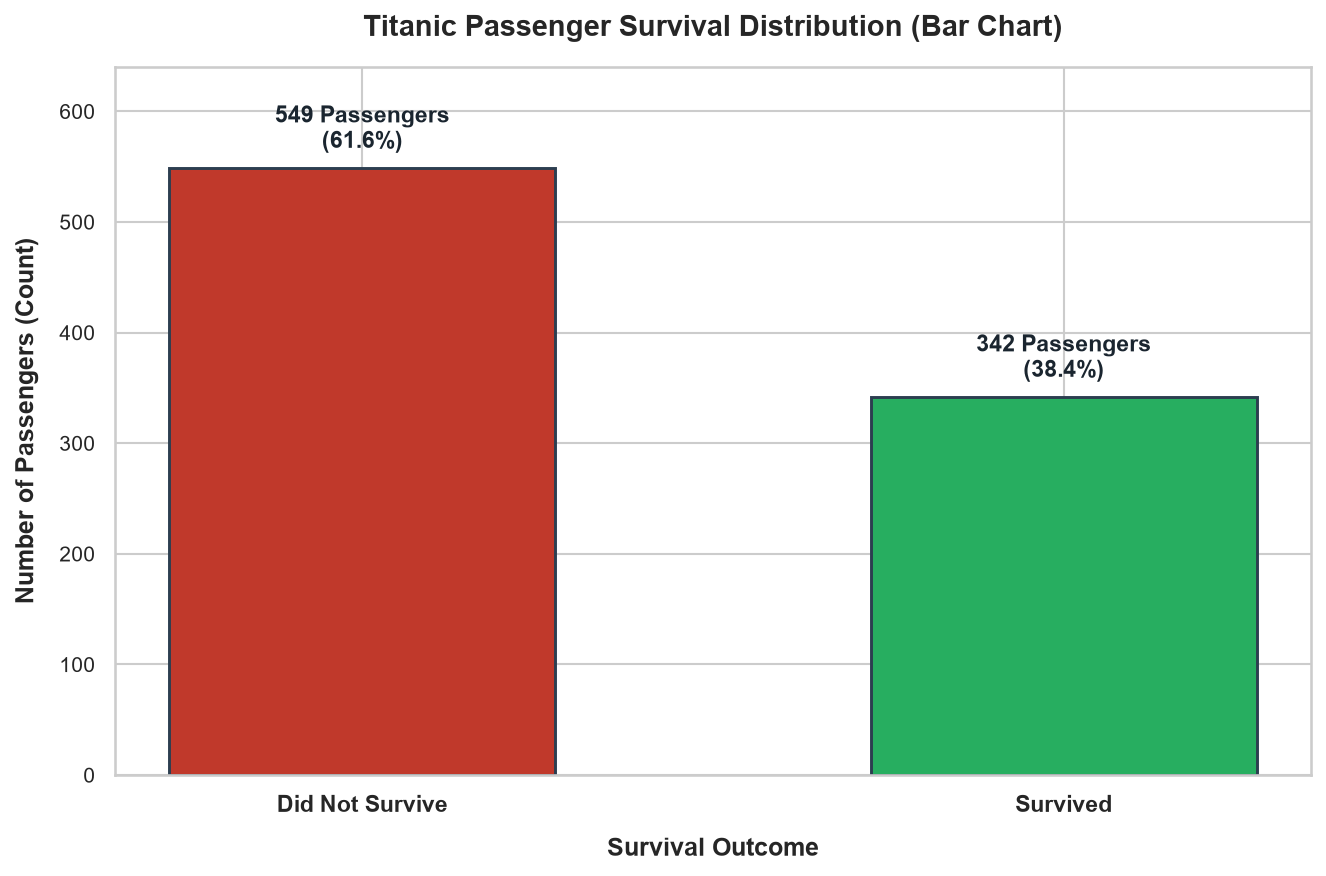

In [5]:
plt.figure(figsize=(9, 6))
colors = ['#c0392b', '#27ae60']

bars = plt.bar(
    summary_df.index,
    summary_df['Count (Frequency)'],
    color=colors,
    edgecolor='#2c3e50',
    linewidth=1.4,
    width=0.55
)

plt.title('Titanic Passenger Survival Distribution (Bar Chart)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Survival Outcome', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Number of Passengers (Count)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylim(0, 640)
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(np.arange(0, 650, 100), fontsize=10)

# Add exact data annotations (Count and Percentage)
for bar, count, pct in zip(bars, summary_df['Count (Frequency)'], summary_df['Percentage (%)']):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 12,
        f'{count:,} Passengers\n({pct:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold',
        color='#1a252f'
    )

plt.tight_layout()
os.makedirs(os.path.join('..', 'charts'), exist_ok=True)
plt.savefig(os.path.join('..', 'charts', 'bar_chart.png'), dpi=300, bbox_inches='tight')
plt.show()


## 5. Visualization 2: Passenger Survival Pie Chart
The Pie Chart encodes proportional share as radial angles and 2D circular sector areas, demonstrating part-to-whole relationships.


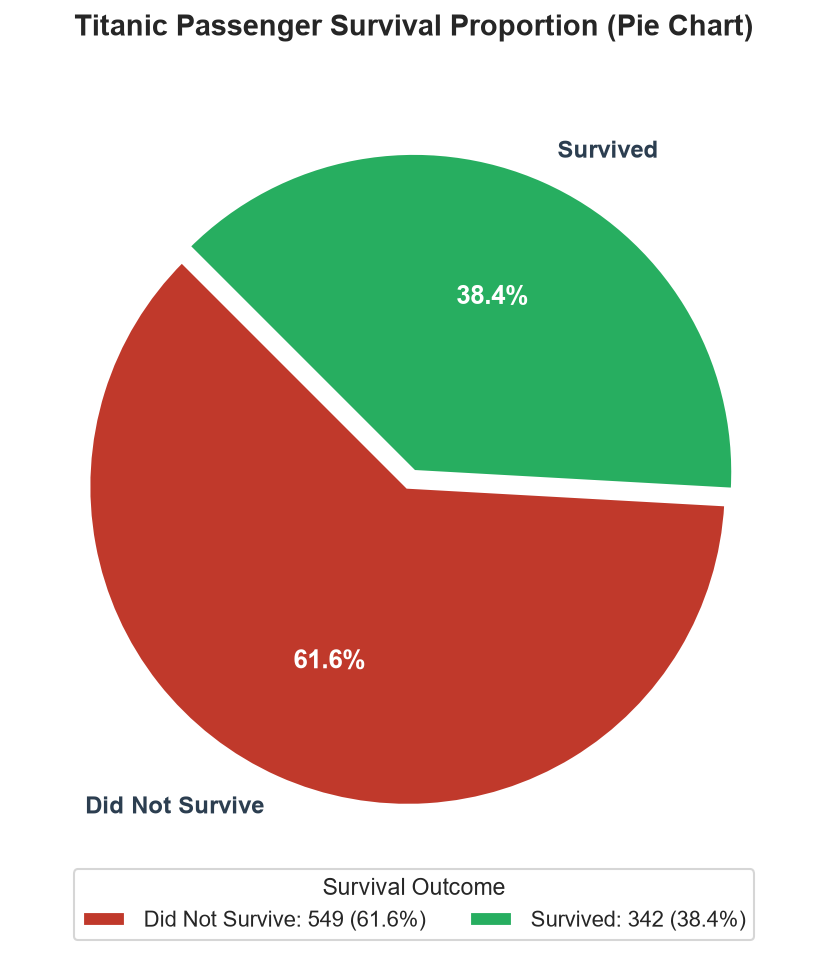

In [6]:
plt.figure(figsize=(8.5, 6.5))

explode = (0.05, 0)
wedges, texts, autotexts = plt.pie(
    summary_df['Count (Frequency)'],
    labels=summary_df.index,
    autopct='%1.1f%%',
    startangle=135,
    explode=explode,
    colors=colors,
    pctdistance=0.6,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'antialiased': True}
)

for t in texts:
    t.set_fontsize(11.5)
    t.set_fontweight('bold')
    t.set_color('#2c3e50')
for at in autotexts:
    at.set_fontsize(12.5)
    at.set_fontweight('bold')
    at.set_color('white')

plt.title('Titanic Passenger Survival Proportion (Pie Chart)', fontsize=14, fontweight='bold', pad=18)

legend_labels = [f'{label}: {count} ({pct:.1f}%)' for label, count, pct in zip(summary_df.index, summary_df['Count (Frequency)'], summary_df['Percentage (%)'])]
plt.legend(
    wedges,
    legend_labels,
    title='Survival Outcome',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.1),
    ncol=2,
    fontsize=10.5,
    title_fontsize=11,
    frameon=True
)

plt.tight_layout()
plt.savefig(os.path.join('..', 'charts', 'pie_chart.png'), dpi=300, bbox_inches='tight')
plt.show()


## 6. Graphical Perception & Interpretation Insights
- **Perceptual Accuracy (Cleveland & McGill):** The bar chart allows viewers to make instantaneous linear comparisons along a shared horizontal axis, minimizing cognitive processing time.
- **Part-to-Whole Representation:** The pie chart clearly conveys that over 60% of the sample did not survive, but lacks a metric axis to easily read absolute counts.
- **Conclusion:** While the pie chart effectively highlights the majority vs. minority proportion, the bar chart communicates both relative magnitude and absolute frequency with superior perceptual precision.
